<a href="https://colab.research.google.com/github/Aldiss1/MPPM_Aldi/blob/main/JS08/JS08-01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 1 — Hierarchical Clustering (Agglomerative)


## Langkah 1 — Import Library

`scipy.cluster.hierarchy` dipakai untuk membangun dendrogram, sedangkan `sklearn.cluster.AgglomerativeClustering` untuk membuat modelnya.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.cluster.hierarchy as sch

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

%matplotlib inline
plt.rcParams["figure.figsize"] = (8, 5)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

## Langkah 2 — Load Dataset & Inspeksi

Dataset dibaca dengan `pandas`, lalu diperiksa struktur dan statistik ringkasnya untuk memastikan tidak ada nilai kosong dan tipe datanya sesuai.

In [3]:
df = pd.read_csv("Mall_Customers.csv")

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Genre                   200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [4]:
df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [5]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000,200.000,200.000,200.000
mean,100.500,38.850,60.560,50.200
std,57.879,13.969,26.265,25.824
min,1.000,18.000,15.000,1.000
25%,50.750,28.750,41.500,34.750
50%,100.500,36.000,61.500,50.000
75%,150.250,49.000,78.000,73.000
max,200.000,70.000,137.000,99.000


**Hasil inspeksi:** 200 baris, 5 kolom, tanpa *missing value*. Empat kolom bertipe numerik dan satu kolom (`Genre`) bertipe objek. Karena klasterisasi membutuhkan jarak numerik, kolom `CustomerID` (hanya identitas) dan `Genre` (kategorikal) tidak dipakai.

## Langkah 3 — Slicing Fitur



In [6]:
X = df.iloc[:, [3, 4]].values
print("Bentuk X:", X.shape)
print("Contoh 5 data pertama:\n", X[:5])

Bentuk X: (200, 2)
Contoh 5 data pertama:
 [[15 39]
 [15 81]
 [16  6]
 [16 77]
 [17 40]]


## Langkah 4 — Visualisasi Sebaran Data

Sebelum clustering, lihat dulu sebaran data mentahnya. Ini penting agar kita tahu apakah data memang punya kecenderungan mengelompok.

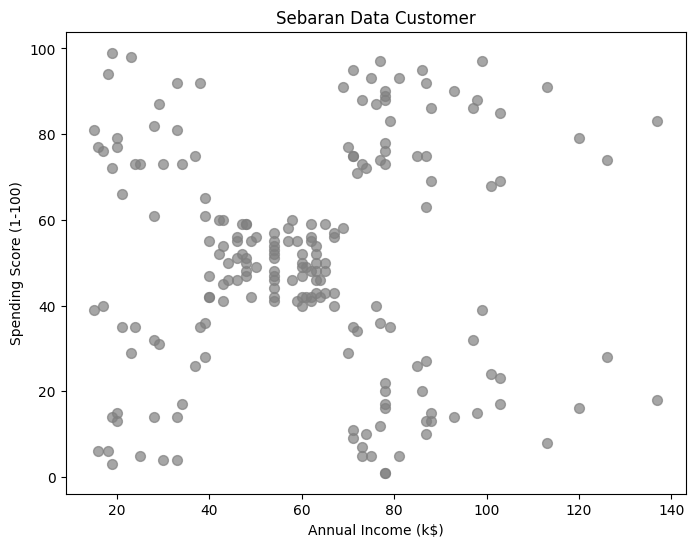

In [7]:
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], s=50, c="gray", alpha=0.7)
plt.title("Sebaran Data Customer")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.show()

Terlihat ada beberapa kelompok yang cukup jelas: income rendah–spending rendah, income rendah–spending tinggi, income sedang–spending sedang, dan seterusnya. Ini tanda bahwa data memang layak diklasterisasi.

## Langkah 5 — Visualisasi Dendrogram



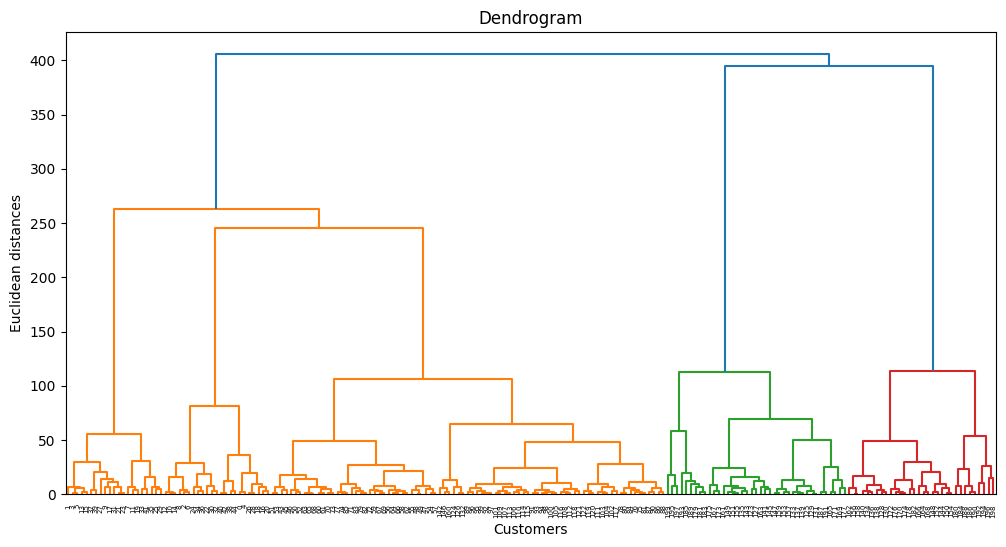

In [8]:
plt.figure(figsize=(12, 6))
dendrogram = sch.dendrogram(sch.linkage(X, method="ward"))
plt.title("Dendrogram")
plt.xlabel("Customers")
plt.ylabel("Euclidean distances")
plt.show()

## Langkah 6 — Menentukan Jumlah Cluster dari Dendrogram

Jumlah cluster ditentukan dengan menarik garis horizontal (*threshold*) pada dendrogram. Jumlah cabang vertikal yang terpotong garis tersebut = jumlah cluster.

Kita coba beberapa nilai threshold untuk melihat pergeseran jumlah cluster.

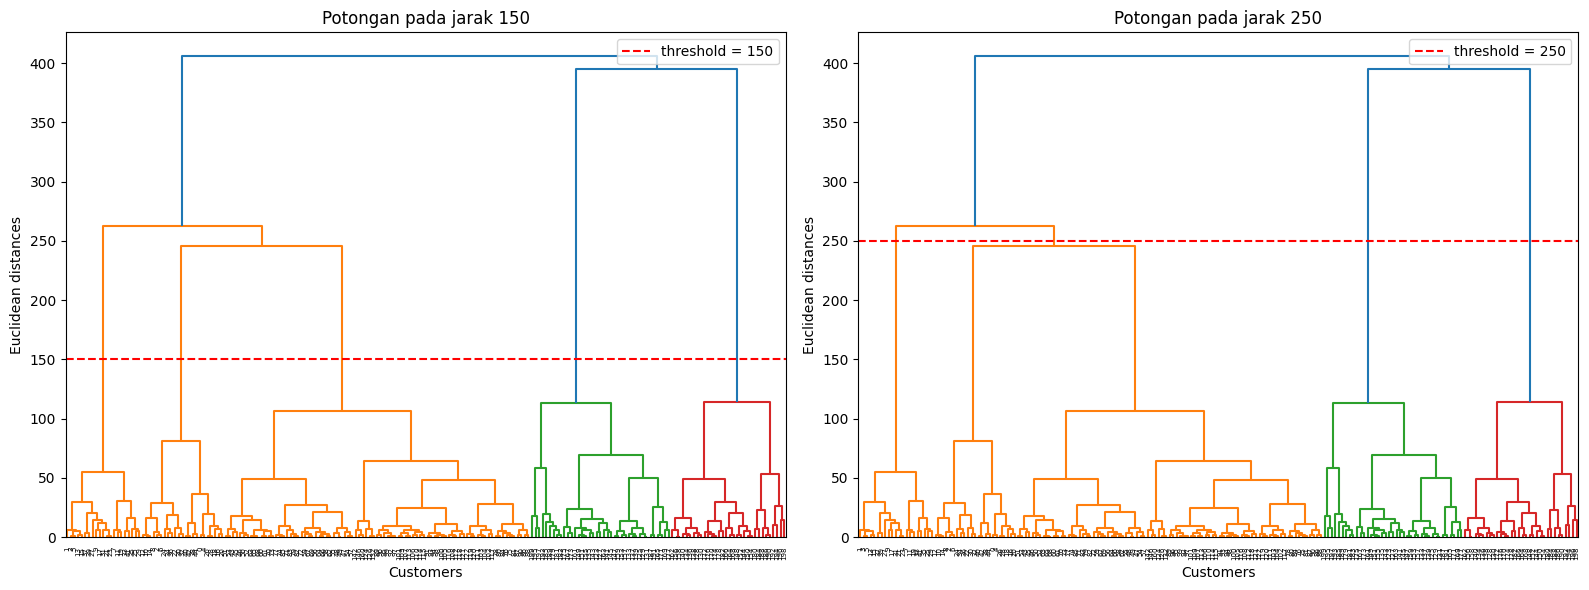

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, threshold in zip(axes, [150, 250]):
    plt.sca(ax)
    sch.dendrogram(sch.linkage(X, method="ward"))
    ax.axhline(y=threshold, color="red", linestyle="--", label=f"threshold = {threshold}")
    ax.set_title(f"Potongan pada jarak {threshold}")
    ax.set_xlabel("Customers")
    ax.set_ylabel("Euclidean distances")
    ax.legend()

plt.tight_layout()
plt.show()

Pada potongan rendah jumlah cluster lebih banyak, sedangkan pada potongan tinggi cluster yang terbentuk lebih sedikit. Untuk memastikannya, jumlah cluster dihitung otomatis dari linkage matrix: sebuah penggabungan menghasilkan cluster baru bila jaraknya melewati threshold.

In [10]:
Z = sch.linkage(X, method="ward")

print(f"{'threshold':>10} | jumlah cluster")
print("-" * 30)
for t in [50, 100, 120, 150, 200, 250, 300]:
    n = int((Z[:, 2] > t).sum()) + 1
    print(f"{t:>10} | {n}")

 threshold | jumlah cluster
------------------------------
        50 | 14
       100 | 8
       120 | 5
       150 | 5
       200 | 5
       250 | 4
       300 | 3


Terlihat bahwa pada rentang threshold **120–200** jumlah cluster stabil di **5**. Di bawah 120 jumlahnya melonjak (cluster terpecah terlalu halus, misal 8 cluster pada threshold 100), sedangkan di atas 200 turun menjadi 4 dan 3. Nilai **5** inilah yang dipakai pada Langkah 7.

## Langkah 7 — Membuat Model Agglomerative



In [11]:
hc = AgglomerativeClustering(n_clusters=5, metric="euclidean", linkage="ward")
y_hc = hc.fit_predict(X)

print("Label unik:", np.unique(y_hc))
print("Jumlah anggota tiap cluster:", np.bincount(y_hc))

Label unik: [0 1 2 3 4]
Jumlah anggota tiap cluster: [32 85 39 21 23]


## Langkah 8 — Visualisasi Hasil Cluster

Setiap cluster diberi satu warna pada scatterplot, supaya bentuk pengelompokannya bisa dibandingkan dengan sebaran data mentah pada Langkah 4.

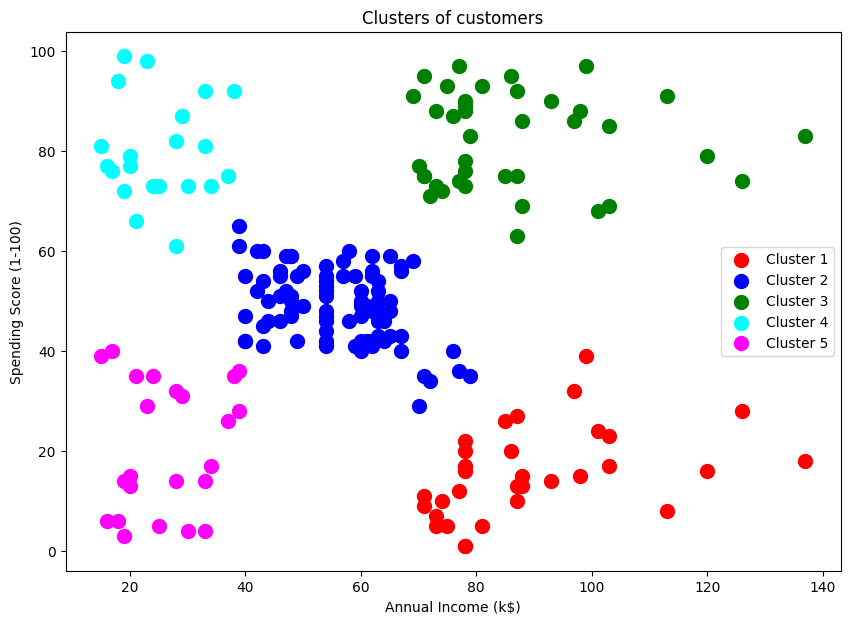

In [12]:
colors = ["red", "blue", "green", "cyan", "magenta"]

plt.figure(figsize=(10, 7))
for i in range(5):
    plt.scatter(
        X[y_hc == i, 0], X[y_hc == i, 1],
        s=100, c=colors[i], label=f"Cluster {i + 1}",
    )
plt.title("Clusters of customers")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend()
plt.show()

Hasilnya lima segmen customer yang cukup masuk akal secara bisnis. Berdasarkan warna pada plot:

| Cluster (warna) | Annual Income | Spending Score | Tafsiran |
|---|---|---|---|
| 1 (merah) | tinggi (≈70–140) | rendah (≈0–40) | mampu tapi hemat — perlu digerakkan promosi |
| 2 (biru) | sedang (≈40–70) | sedang (≈35–60) | customer moderat / mayoritas |
| 3 (hijau) | tinggi (≈70–105) | tinggi (≈60–100) | premium — target utama |
| 4 (cyan) | rendah (≈15–40) | tinggi (≈60–100) | impulsif — sensitif diskon |
| 5 (magenta) | rendah (≈15–40) | rendah (≈0–40) | hemat — prioritas rendah |

Pemisahan ini terjadi pada **dua sumbu sekaligus**: income saja tidak cukup, karena customer ber-income tinggi bisa masuk cluster 1 (hemat) atau cluster 3 (premium).

## Langkah 9 — Evaluasi dengan Silhouette Coefficient

Silhouette mengukur seberapa mirip sebuah data dengan clusternya sendiri dibanding cluster terdekat lain. Nilainya **-1 s/d 1**; makin mendekati 1 makin baik.

In [13]:
silhouette_avg = silhouette_score(X, y_hc)
print(f"Silhouette Coefficient (k=5): {silhouette_avg:.4f}")

Silhouette Coefficient (k=5): 0.5530


**Kesimpulan Lab 1**

- Dendrogram menunjukkan struktur hierarki data customer. Pengecekan otomatis pada linkage matrix memperlihatkan jumlah cluster **stabil di 5 pada threshold 120–200**, dan 5 adalah nilai yang dipakai modul.
- Model `AgglomerativeClustering(n_clusters=5, linkage="ward")` menghasilkan Silhouette Coefficient **≈ 0,553**, artinya struktur cluster cukup baik.
- Kelima cluster dapat ditafsirkan sebagai segmen customer berdasarkan kombinasi *income* dan *spending*, bukan hanya salah satu variabel saja.
- Eksperimen `k = 2..10` menunjukkan **k = 5 memberi Silhouette tertinggi (0,553)** — jadi pilihan dari dendrogram juga yang terbaik secara metrik. Nilai turun setelah k = 6 karena cluster mulai dipecah melebihi struktur alami data.
- Ukuran cluster tidak seimbang (32, 85, 39, 21, 23). Ini normal pada data customer nyata dan justru informasi berguna: cluster 2 adalah mayoritas pasar.